In [1]:
%pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (60000, 784)
Testing Shape: (10000, 784)


In [4]:
# Use digit 0 as normal data
x_train_normal = x_train[y_train == 0]
x_test_normal = x_test[y_test == 0]

# Use other digits as anomalies
x_test_anomaly = x_test[y_test != 0]

print("Normal Images:", len(x_train_normal))
print("Anomaly Images:", len(x_test_anomaly))

Normal Images: 5923
Anomaly Images: 9020


In [5]:
# Encoder
encoder_input = keras.Input(shape=(784,))
x = layers.Dense(128, activation='relu')(encoder_input)
latent = layers.Dense(32, activation='relu')(x)

encoder = keras.Model(encoder_input, latent)

# Decoder
decoder_input = keras.Input(shape=(32,))
x = layers.Dense(128, activation='relu')(decoder_input)
output = layers.Dense(784, activation='sigmoid')(x)

decoder = keras.Model(decoder_input, output)

# Combine encoder and decoder
autoencoder = keras.Sequential([encoder, decoder])

# Display model
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ functional (Functional)              │ (None, 32)                  │         104,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ functional_1 (Functional)            │ (None, 784)                 │         105,360 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train using normal images
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.1093 - mae: 0.2383 - val_loss: 0.0590 - val_mae: 0.1266
Epoch 2/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0509 - mae: 0.1143 - val_loss: 0.0425 - val_mae: 0.0991
Epoch 3/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0403 - mae: 0.0963 - val_loss: 0.0361 - val_mae: 0.0908
Epoch 4/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0349 - mae: 0.0885 - val_loss: 0.0321 - val_mae: 0.0846
Epoch 5/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0309 - mae: 0.0816 - val_loss: 0.0282 - val_mae: 0.0774
Epoch 6/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0268 - mae: 0.0737 - val_loss: 0.0244 - val_mae: 0.0691
Epoch 7/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0237 - mae: 0.0668 - val_loss: 0.0220 - val_mae: 0.0636
Epoch 8/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0213 - mae: 0.0619 - val_loss: 0.0206 - val_mae: 0.0603
Epoch 9/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.019

In [7]:
# Reconstruct normal images
reconstructed = autoencoder.predict(x_test_normal)

# Calculate reconstruction error
errors = np.mean((x_test_normal - reconstructed) ** 2, axis=1)

# Set threshold
threshold = np.percentile(errors, 95)

print("Anomaly Threshold:", threshold)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Anomaly Threshold: 0.03413146


In [8]:
# Select normal and anomalous images
test_data = np.concatenate([
    x_test_normal[:500],
    x_test_anomaly[:500]
])

# Reconstruct images
predictions = autoencoder.predict(test_data)

# Calculate errors
test_errors = np.mean((test_data - predictions) ** 2, axis=1)

# Detect anomalies
results = test_errors > threshold

# Display results
for i in range(10):
    print("Image", i + 1, ":", "Anomaly" if results[i] else "Normal")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Image 1 : Normal
Image 2 : Normal
Image 3 : Normal
Image 4 : Normal
Image 5 : Normal
Image 6 : Normal
Image 7 : Normal
Image 8 : Normal
Image 9 : Normal
Image 10 : Normal


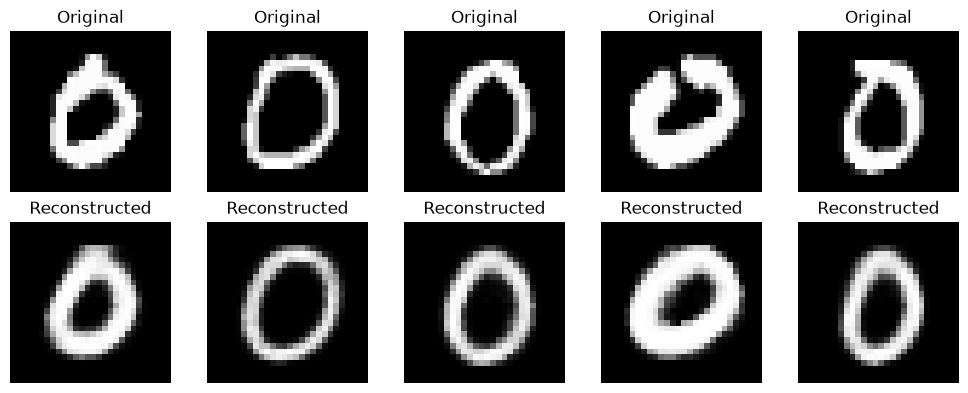

In [9]:
plt.figure(figsize=(10, 4))

for i in range(5):
    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(test_data[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 5, i + 6)
    plt.imshow(predictions[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

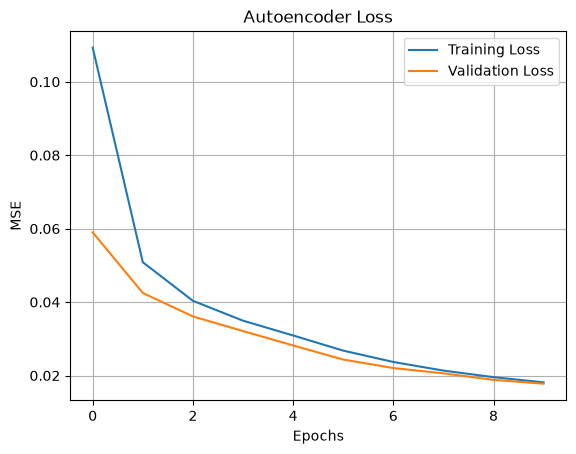

In [10]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE')

plt.legend()
plt.grid()
plt.show()